In [1]:
import pandas as pd
import numpy as np

# Load cleaned transaction data
DATA_FILE = "../data/clean/transactions_clean.parquet"
transactions = pd.read_parquet(DATA_FILE)

# Recreate transaction line value
transactions["line_value"] = (
    transactions["Quantity"] * transactions["Price"]
)

# Define valid purchase rows
valid_purchase_rows = transactions[
    transactions["Customer ID"].notna()
    & (~transactions["is_cancellation"])
    & (transactions["line_type"] == "product")
].copy()

# Aggregate purchases at customer-invoice level
purchase_invoices = (
    valid_purchase_rows
    .groupby(["Customer ID", "Invoice"])
    .agg(
        purchase_date=("InvoiceDate", "min"),
        purchase_value=("line_value", "sum")
    )
    .reset_index()
)

# Calculate reference date
snapshot_date = (
    transactions["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Calculate Recency and Frequency
rfm = (
    purchase_invoices
    .groupby("Customer ID")
    .agg(
        last_purchase_date=("purchase_date", "max"),
        frequency=("Invoice", "nunique")
    )
    .reset_index()
)

rfm["recency"] = (
    snapshot_date - rfm["last_purchase_date"]
).dt.days

# Calculate Monetary value using products and adjustments
monetary_rows = transactions[
    transactions["Customer ID"].notna()
    & transactions["line_type"].isin(["product", "adjustment"])
]

customer_monetary = (
    monetary_rows
    .groupby("Customer ID")
    .agg(
        monetary_value=("line_value", "sum")
    )
    .reset_index()
)

# Merge all three RFM metrics
rfm = rfm.merge(
    customer_monetary,
    on="Customer ID",
    how="left"
)

rfm["monetary_value"] = rfm["monetary_value"].round(2)

print("RFM dataset reconstructed successfully!")
print("Customers:", len(rfm))
print("Total purchase invoices:", rfm["frequency"].sum())
print("Reference date:", snapshot_date)

display(rfm.head())

RFM dataset reconstructed successfully!
Customers: 5853
Total purchase invoices: 36597
Reference date: 2011-12-10 12:50:00


,Customer ID,last_purchase_date,frequency,recency,monetary_value
0,12346,2011-01-18 10:01:00,3,326,-263.68
1,12347,2011-12-07 15:52:00,8,2,4921.53
2,12348,2011-09-25 13:13:00,5,75,1658.40
3,12349,2011-11-21 09:51:00,3,19,3654.54
4,12350,2011-02-02 16:01:00,1,310,294.40


In [2]:
# Calculate descriptive statistics for RFM metrics
rfm_summary = rfm[
    ["recency", "frequency", "monetary_value"]
].describe().T

# Add skewness to understand distribution shape
rfm_summary["skewness"] = rfm[
    ["recency", "frequency", "monetary_value"]
].skew()

display(
    rfm_summary.style.format("{:,.2f}")
)

,count,mean,std,min,25%,50%,75%,max,skewness
recency,"5,853.00",200.17,208.51,1.00,25.00,95.00,379.00,739.00,0.89
frequency,"5,853.00",6.25,12.75,1.00,1.00,3.00,7.00,373.00,12.04
monetary_value,"5,853.00","2,784.28","13,722.45","-3,767.20",331.26,840.08,"2,172.47","570,380.61",26.74


In [3]:
# Calculate quantiles for each RFM metric
quantiles = [0, 0.20, 0.40, 0.60, 0.80, 1.00]

recency_quantiles = rfm["recency"].quantile(quantiles)
frequency_quantiles = rfm["frequency"].quantile(quantiles)
monetary_quantiles = rfm.loc[
    rfm["monetary_value"] > 0,
    "monetary_value"
].quantile(quantiles)

# Combine into one table
quantile_summary = pd.DataFrame({
    "Percentile": ["0%", "20%", "40%", "60%", "80%", "100%"],
    "Recency": recency_quantiles.values,
    "Frequency": frequency_quantiles.values,
    "Positive monetary value": monetary_quantiles.values
})

display(
    quantile_summary.style.format({
        "Recency": "{:,.2f}",
        "Frequency": "{:,.2f}",
        "Positive monetary value": "£{:,.2f}"
    })
)

# Check how many customers have non-positive monetary value
print("\nMonetary value distribution:")
print("Negative:", (rfm["monetary_value"] < 0).sum())
print("Zero:", (rfm["monetary_value"] == 0).sum())
print("Positive:", (rfm["monetary_value"] > 0).sum())

# Check unique frequency values
print("\nNumber of unique frequency values:",
      rfm["frequency"].nunique())

print("Frequency values occurring most often:")
display(rfm["frequency"].value_counts().head(10))

,Percentile,Recency,Frequency,Positive monetary value
0,0%,1.00,1.00,£2.90
1,20%,19.00,1.00,£279.77
2,40%,59.00,2.00,£599.38
3,60%,187.00,4.00,"£1,185.02"
4,80%,409.00,8.00,"£2,843.15"
5,100%,739.00,373.00,"£570,380.61"



Monetary value distribution:
Negative: 7
Zero: 20
Positive: 5826

Number of unique frequency values: 87
Frequency values occurring most often:


frequency
1     1619
2      945
3      659
4      489
5      355
6      278
7      218
8      173
9      156
11     125
Name: count, dtype: int64

In [4]:
frequency_distribution = (
    rfm["frequency"]
    .value_counts()
    .sort_index()
    .reset_index()
)

frequency_distribution.columns = ["Frequency", "Customer count"]

frequency_distribution["Customer share (%)"] = (
    frequency_distribution["Customer count"]
    / len(rfm) * 100
)

display(
    frequency_distribution.head(25).style.format({
        "Customer share (%)": "{:.2f}%"
    })
)

print("Customers with 1 purchase:",
      (rfm["frequency"] == 1).sum())

print("Customers with 2–3 purchases:",
      rfm["frequency"].between(2, 3).sum())

print("Customers with 4–8 purchases:",
      rfm["frequency"].between(4, 8).sum())

print("Customers with more than 8 purchases:",
      (rfm["frequency"] > 8).sum())

,Frequency,Customer count,Customer share (%)
0,1,1619,27.66%
1,2,945,16.15%
2,3,659,11.26%
3,4,489,8.35%
4,5,355,6.07%
5,6,278,4.75%
6,7,218,3.72%
7,8,173,2.96%
8,9,156,2.67%
9,10,97,1.66%


Customers with 1 purchase: 1619
Customers with 2–3 purchases: 1604
Customers with 4–8 purchases: 1513
Customers with more than 8 purchases: 1117


In [5]:
# 1. Recency score: lower recency = better score
rfm["R_score"] = pd.qcut(
    rfm["recency"],
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# 2. Frequency score: higher frequency = better score
rfm["F_score"] = np.select(
    [
        rfm["frequency"] == 1,
        rfm["frequency"] == 2,
        rfm["frequency"].between(3, 4),
        rfm["frequency"].between(5, 8),
        rfm["frequency"] > 8
    ],
    [1, 2, 3, 4, 5]
).astype(int)

# 3. Monetary score: score positive values separately
rfm["M_score"] = 0

positive_mask = rfm["monetary_value"] > 0

rfm.loc[positive_mask, "M_score"] = pd.qcut(
    rfm.loc[positive_mask, "monetary_value"],
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# 4. Combined RFM score
rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

# 5. Inspect results
display(rfm.head(10))

print("RFM score distribution:")
print(rfm[["R_score", "F_score", "M_score"]].describe())

print("\nNon-positive monetary customers:")
print((rfm["M_score"] == 0).sum())

print("\nMissing scores:")
print(rfm[["R_score", "F_score", "M_score"]].isna().sum())

,Customer ID,last_purchase_date,frequency,recency,monetary_value,R_score,F_score,M_score,RFM_score
0,12346,2011-01-18 10:01:00,3,326,-263.68,2,3,0,230
1,12347,2011-12-07 15:52:00,8,2,4921.53,5,4,5,545
2,12348,2011-09-25 13:13:00,5,75,1658.40,3,4,4,344
3,12349,2011-11-21 09:51:00,3,19,3654.54,5,3,5,535
4,12350,2011-02-02 16:01:00,1,310,294.40,2,1,2,212
5,12351,2010-11-29 15:23:00,1,375,300.93,2,1,2,212
6,12352,2011-11-03 14:37:00,9,36,1609.21,4,5,4,454
7,12353,2011-05-19 17:47:00,2,204,406.76,2,2,2,222
8,12354,2011-04-21 13:11:00,1,232,1079.40,2,1,3,213
9,12355,2011-05-09 13:49:00,2,214,947.61,2,2,3,223


RFM score distribution:
           R_score      F_score      M_score
count  5853.000000  5853.000000  5853.000000
mean      3.008713     2.841961     2.985819
std       1.417023     1.477029     1.425756
min       1.000000     1.000000     0.000000
25%       2.000000     1.000000     2.000000
50%       3.000000     3.000000     3.000000
75%       4.000000     4.000000     4.000000
max       5.000000     5.000000     5.000000

Non-positive monetary customers:
27

Missing scores:
R_score    0
F_score    0
M_score    0
dtype: int64


In [6]:
# Count customers at each score level
for column in ["R_score", "F_score", "M_score"]:
    print(f"\n{column} distribution:")
    distribution = (
        rfm[column]
        .value_counts()
        .sort_index()
        .rename_axis("Score")
        .reset_index(name="Customers")
    )

    distribution["Share (%)"] = (
        distribution["Customers"] / len(rfm) * 100
    )

    display(
        distribution.style.format({
            "Share (%)": "{:.2f}%"
        })
    )

# Inspect the most common combined RFM scores
print("\nTop 15 most common combined RFM scores:")
display(
    rfm["RFM_score"]
    .value_counts()
    .head(15)
    .rename_axis("RFM score")
    .reset_index(name="Customers")
)


R_score distribution:


,Score,Customers,Share (%)
0,1,1163,19.87%
1,2,1173,20.04%
2,3,1155,19.73%
3,4,1174,20.06%
4,5,1188,20.30%



F_score distribution:


,Score,Customers,Share (%)
0,1,1619,27.66%
1,2,945,16.15%
2,3,1148,19.61%
3,4,1024,17.50%
4,5,1117,19.08%



M_score distribution:


,Score,Customers,Share (%)
0,0,27,0.46%
1,1,1166,19.92%
2,2,1165,19.90%
3,3,1165,19.90%
4,4,1165,19.90%
5,5,1165,19.90%



Top 15 most common combined RFM scores:


,RFM score,Customers
0,555,460
1,111,433
2,211,250
3,455,244
4,112,213
5,344,152
6,444,145
7,233,128
8,222,126
9,212,125


In [7]:
conditions = [
    rfm["M_score"] == 0,

    (rfm["R_score"] >= 4) &
    (rfm["F_score"] >= 4) &
    (rfm["M_score"] >= 4),

    (rfm["R_score"] >= 3) &
    (rfm["F_score"] >= 4),

    (rfm["R_score"] >= 4) &
    (rfm["F_score"].between(2, 3)),

    (rfm["R_score"] == 5) &
    (rfm["F_score"] == 1),

    (rfm["R_score"] <= 2) &
    (rfm["F_score"] >= 3),

    (rfm["R_score"] <= 2) &
    (rfm["F_score"] <= 2)
]

choices = [
    "Non-positive Value",
    "Champions",
    "Loyal Customers",
    "Potential Loyalists",
    "New Customers",
    "At Risk",
    "Hibernating"
]

rfm["customer_segment"] = np.select(
    conditions,
    choices,
    default="Other / Developing"
)

print("Customer segment distribution:")
display(
    rfm["customer_segment"]
    .value_counts()
    .rename_axis("Customer Segment")
    .reset_index(name="Customers")
)

Customer segment distribution:


,Customer Segment,Customers
0,Hibernating,1615
1,Champions,1266
2,Other / Developing,859
3,Potential Loyalists,716
4,At Risk,705
5,Loyal Customers,590
6,New Customers,75
7,Non-positive Value,27


In [8]:
segment_analysis = (
    rfm.groupby("customer_segment")
    .agg(
        customers=("Customer ID", "nunique"),
        total_revenue=("monetary_value", "sum"),
        average_revenue=("monetary_value", "mean"),
        median_revenue=("monetary_value", "median"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean")
    )
    .reset_index()
)

total_revenue = rfm["monetary_value"].sum()

segment_analysis["customer_share_pct"] = (
    segment_analysis["customers"] / len(rfm) * 100
)

segment_analysis["revenue_share_pct"] = (
    segment_analysis["total_revenue"] / total_revenue * 100
)

segment_analysis = segment_analysis.sort_values(
    "total_revenue", ascending=False
)

display(
    segment_analysis.style.format({
        "total_revenue": "£{:,.2f}",
        "average_revenue": "£{:,.2f}",
        "median_revenue": "£{:,.2f}",
        "average_recency": "{:.1f}",
        "average_frequency": "{:.2f}",
        "customer_share_pct": "{:.2f}%",
        "revenue_share_pct": "{:.2f}%"
    })
)

print("Total segment revenue: £{:,.2f}".format(
    segment_analysis["total_revenue"].sum()
))

print("Total RFM cohort revenue: £{:,.2f}".format(total_revenue))

,customer_segment,customers,total_revenue,average_revenue,median_revenue,average_recency,average_frequency,customer_share_pct,revenue_share_pct
1,Champions,1266,"£11,304,191.61","£8,929.06","£3,911.28",19.8,17.25,21.63%,69.37%
3,Loyal Customers,590,"£1,662,469.46","£2,817.74","£1,839.37",85.7,8.28,10.08%,10.20%
0,At Risk,705,"£1,343,278.71","£1,905.36","£1,124.15",358.8,5.47,12.05%,8.24%
7,Potential Loyalists,716,"£686,589.60",£958.92,£743.88,25.3,2.88,12.23%,4.21%
2,Hibernating,1615,"£676,207.38",£418.70,£288.10,453.8,1.31,27.59%,4.15%
6,Other / Developing,859,"£605,092.61",£704.42,£473.65,96.1,2.01,14.68%,3.71%
4,New Customers,75,"£25,517.74",£340.24,£261.11,11.3,1.00,1.28%,0.16%
5,Non-positive Value,27,"£-6,934.52",£-256.83,£0.00,320.8,1.52,0.46%,-0.04%


Total segment revenue: £16,296,412.59
Total RFM cohort revenue: £16,296,412.59


In [9]:
segment_score_profile = (
    rfm.groupby("customer_segment")
    .agg(
        customers=("Customer ID", "nunique"),
        avg_R_score=("R_score", "mean"),
        avg_F_score=("F_score", "mean"),
        avg_M_score=("M_score", "mean"),
        min_recency=("recency", "min"),
        max_recency=("recency", "max"),
        min_frequency=("frequency", "min"),
        max_frequency=("frequency", "max")
    )
    .reset_index()
)

display(
    segment_score_profile.style.format({
        "avg_R_score": "{:.2f}",
        "avg_F_score": "{:.2f}",
        "avg_M_score": "{:.2f}"
    })
)

,customer_segment,customers,avg_R_score,avg_F_score,avg_M_score,min_recency,max_recency,min_frequency,max_frequency
0,At Risk,705,1.69,3.49,3.37,188,725,3,155
1,Champions,1266,4.58,4.68,4.66,1,59,5,373
2,Hibernating,1615,1.42,1.31,1.73,189,738,1,2
3,Loyal Customers,590,3.36,4.32,3.91,1,187,5,34
4,New Customers,75,5.00,1.00,1.59,1,19,1,1
5,Non-positive Value,27,2.22,1.37,0.00,8,739,1,7
6,Other / Developing,859,3.19,1.86,2.28,20,187,1,4
7,Potential Loyalists,716,4.42,2.62,2.81,1,59,2,4


In [10]:
# Create a refined segment column
rfm["customer_segment_refined"] = rfm["customer_segment"]

# Separate high-value at-risk customers
high_value_at_risk = (
    (rfm["customer_segment"] == "At Risk")
    & (rfm["F_score"] >= 3)
    & (rfm["M_score"] >= 4)
)

rfm.loc[
    high_value_at_risk,
    "customer_segment_refined"
] = "High-value At Risk"

# Recalculate segment distribution
display(
    rfm["customer_segment_refined"]
    .value_counts()
    .rename_axis("Customer Segment")
    .reset_index(name="Customers")
)

,Customer Segment,Customers
0,Hibernating,1615
1,Champions,1266
2,Other / Developing,859
3,Potential Loyalists,716
4,Loyal Customers,590
5,At Risk,388
6,High-value At Risk,317
7,New Customers,75
8,Non-positive Value,27


In [11]:
refined_segment_analysis = (
    rfm.groupby("customer_segment_refined")
    .agg(
        customers=("Customer ID", "nunique"),
        total_revenue=("monetary_value", "sum"),
        average_revenue=("monetary_value", "mean"),
        median_revenue=("monetary_value", "median"),
        average_recency=("recency", "mean"),
        average_frequency=("frequency", "mean")
    )
    .reset_index()
)

total_revenue = rfm["monetary_value"].sum()

refined_segment_analysis["customer_share_pct"] = (
    refined_segment_analysis["customers"] / len(rfm) * 100
)

refined_segment_analysis["revenue_share_pct"] = (
    refined_segment_analysis["total_revenue"] / total_revenue * 100
)

refined_segment_analysis = refined_segment_analysis.sort_values(
    "total_revenue", ascending=False
)

display(
    refined_segment_analysis.style.format({
        "total_revenue": "£{:,.2f}",
        "average_revenue": "£{:,.2f}",
        "median_revenue": "£{:,.2f}",
        "average_recency": "{:.1f}",
        "average_frequency": "{:.2f}",
        "customer_share_pct": "{:.2f}%",
        "revenue_share_pct": "{:.2f}%"
    })
)

print(
    "Revenue reconciliation: £{:,.2f}".format(
        refined_segment_analysis["total_revenue"].sum()
    )
)

print(
    "RFM cohort revenue: £{:,.2f}".format(total_revenue)
)

assert refined_segment_analysis["customers"].sum() == len(rfm)
assert abs(
    refined_segment_analysis["total_revenue"].sum() - total_revenue
) < 0.01

,customer_segment_refined,customers,total_revenue,average_revenue,median_revenue,average_recency,average_frequency,customer_share_pct,revenue_share_pct
1,Champions,1266,"£11,304,191.61","£8,929.06","£3,911.28",19.8,17.25,21.63%,69.37%
4,Loyal Customers,590,"£1,662,469.46","£2,817.74","£1,839.37",85.7,8.28,10.08%,10.20%
3,High-value At Risk,317,"£1,058,581.12","£3,339.37","£1,964.14",350.0,7.44,5.42%,6.50%
8,Potential Loyalists,716,"£686,589.60",£958.92,£743.88,25.3,2.88,12.23%,4.21%
2,Hibernating,1615,"£676,207.38",£418.70,£288.10,453.8,1.31,27.59%,4.15%
7,Other / Developing,859,"£605,092.61",£704.42,£473.65,96.1,2.01,14.68%,3.71%
0,At Risk,388,"£284,697.59",£733.76,£743.58,366.0,3.86,6.63%,1.75%
5,New Customers,75,"£25,517.74",£340.24,£261.11,11.3,1.00,1.28%,0.16%
6,Non-positive Value,27,"£-6,934.52",£-256.83,£0.00,320.8,1.52,0.46%,-0.04%


Revenue reconciliation: £16,296,412.59
RFM cohort revenue: £16,296,412.59


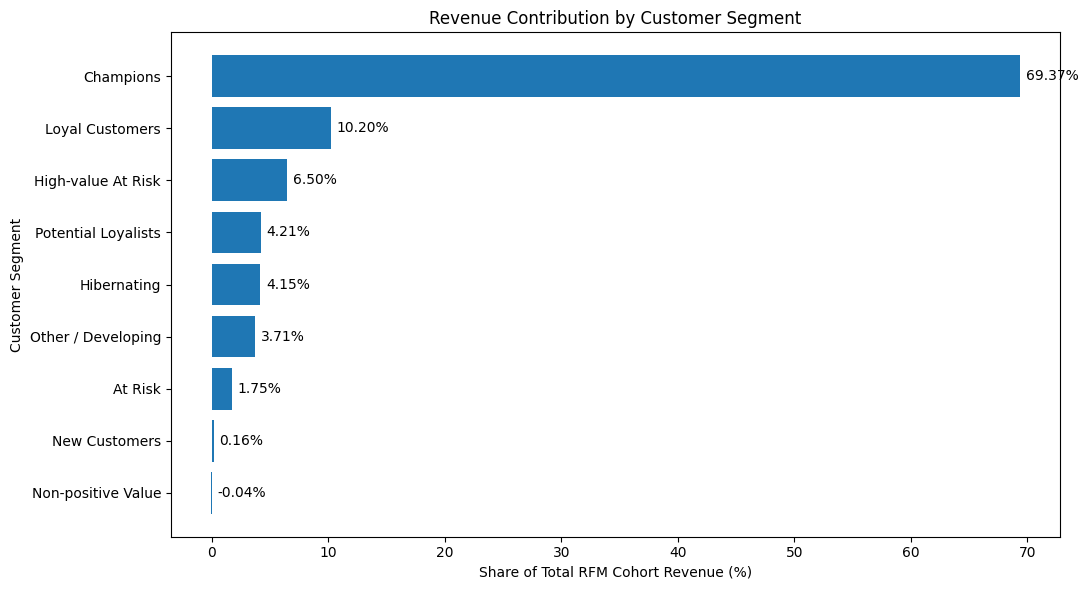

In [12]:
import matplotlib.pyplot as plt

plot_data = refined_segment_analysis.sort_values(
    "revenue_share_pct",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_data["customer_segment_refined"],
    plot_data["revenue_share_pct"]
)

plt.xlabel("Share of Total RFM Cohort Revenue (%)")
plt.ylabel("Customer Segment")
plt.title("Revenue Contribution by Customer Segment")

for index, value in enumerate(plot_data["revenue_share_pct"]):
    plt.text(
        value + 0.5,
        index,
        f"{value:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [13]:
# 1. Filter cancellation transactions with an identified customer
cancellation_rows = transactions[
    transactions["is_cancellation"]
    & transactions["Customer ID"].notna()
].copy()

# 2. Aggregate cancellation activity at customer level
customer_cancellations = (
    cancellation_rows
    .groupby("Customer ID")
    .agg(
        cancellation_invoices=("Invoice", "nunique"),
        cancellation_rows=("Invoice", "size"),
        cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

# 3. Merge cancellation metrics with the RFM customer table
rfm = rfm.merge(
    customer_cancellations,
    on="Customer ID",
    how="left"
)

# 4. Customers without cancellations receive zero values
cancellation_columns = [
    "cancellation_invoices",
    "cancellation_rows",
    "cancellation_value"
]

rfm[cancellation_columns] = (
    rfm[cancellation_columns].fillna(0)
)

rfm["has_cancellation"] = (
    rfm["cancellation_invoices"] > 0
)

# 5. Check the results
print("RFM customer count:", len(rfm))
print("Customers with at least one cancellation:",
      rfm["has_cancellation"].sum())
print("Customers without cancellations:",
      (~rfm["has_cancellation"]).sum())
print("Total cancellation invoices:",
      rfm["cancellation_invoices"].sum())
print("Total cancellation rows:",
      rfm["cancellation_rows"].sum())
print("Total cancellation value: £{:,.2f}".format(
    rfm["cancellation_value"].sum()
))

display(rfm[
    [
        "Customer ID",
        "customer_segment_refined",
        "cancellation_invoices",
        "cancellation_rows",
        "cancellation_value",
        "has_cancellation"
    ]
].head(10))

RFM customer count: 5853
Customers with at least one cancellation: 2496
Customers without cancellations: 3357
Total cancellation invoices: 7794.0
Total cancellation rows: 18276.0
Total cancellation value: £-964,661.94


,Customer ID,customer_segment_refined,cancellation_invoices,cancellation_rows,cancellation_value,has_cancellation
0,12346,Non-positive Value,5.0,14.0,-77621.14,True
1,12347,Champions,0.0,0.0,0.00,False
2,12348,Loyal Customers,0.0,0.0,0.00,False
3,12349,Potential Loyalists,1.0,5.0,-24.15,True
4,12350,Hibernating,0.0,0.0,0.00,False
5,12351,Hibernating,0.0,0.0,0.00,False
6,12352,Champions,3.0,10.0,-960.63,True
7,12353,Hibernating,0.0,0.0,0.00,False
8,12354,Hibernating,0.0,0.0,0.00,False
9,12355,Hibernating,0.0,0.0,0.00,False


In [14]:
# All cancellation records with an identified Customer ID
all_identified_cancellations = transactions[
    transactions["is_cancellation"]
    & transactions["Customer ID"].notna()
].copy()

# Cancellation records belonging to customers in the RFM cohort
rfm_customer_ids = set(rfm["Customer ID"])

rfm_cancellations = all_identified_cancellations[
    all_identified_cancellations["Customer ID"].isin(rfm_customer_ids)
]

# Cancellation records belonging to identified customers outside the RFM cohort
excluded_cancellations = all_identified_cancellations[
    ~all_identified_cancellations["Customer ID"].isin(rfm_customer_ids)
]

print("ALL IDENTIFIED CUSTOMERS")
print("Cancellation rows:",
      len(all_identified_cancellations))
print("Unique cancellation invoices:",
      all_identified_cancellations["Invoice"].nunique())
print("Cancellation value: £{:,.2f}".format(
    all_identified_cancellations["line_value"].sum()
))

print("\nRFM COHORT")
print("Cancellation rows:", len(rfm_cancellations))
print("Unique cancellation invoices:",
      rfm_cancellations["Invoice"].nunique())
print("Cancellation value: £{:,.2f}".format(
    rfm_cancellations["line_value"].sum()
))

print("\nCUSTOMERS EXCLUDED FROM RFM")
print("Unique customers:",
      excluded_cancellations["Customer ID"].nunique())
print("Cancellation rows:", len(excluded_cancellations))
print("Unique cancellation invoices:",
      excluded_cancellations["Invoice"].nunique())
print("Cancellation value: £{:,.2f}".format(
    excluded_cancellations["line_value"].sum()
))

ALL IDENTIFIED CUSTOMERS
Cancellation rows: 18446
Unique cancellation invoices: 7901
Cancellation value: £-1,087,882.14

RFM COHORT
Cancellation rows: 18276
Unique cancellation invoices: 7794
Cancellation value: £-964,661.94

CUSTOMERS EXCLUDED FROM RFM
Unique customers: 76
Cancellation rows: 170
Unique cancellation invoices: 107
Cancellation value: £-123,220.20


In [15]:
# Aggregate cancellation metrics by refined customer segment
cancellation_segment_analysis = (
    rfm.groupby("customer_segment_refined")
    .agg(
        customers=("Customer ID", "nunique"),
        customers_with_cancellations=("has_cancellation", "sum"),
        total_cancellation_invoices=("cancellation_invoices", "sum"),
        total_cancellation_rows=("cancellation_rows", "sum"),
        total_cancellation_value=("cancellation_value", "sum")
    )
    .reset_index()
)

# Calculate cancellation incidence and intensity
cancellation_segment_analysis["cancellation_rate_pct"] = (
    cancellation_segment_analysis["customers_with_cancellations"]
    / cancellation_segment_analysis["customers"] * 100
)

cancellation_segment_analysis["avg_cancellation_invoices"] = (
    cancellation_segment_analysis["total_cancellation_invoices"]
    / cancellation_segment_analysis["customers"]
)

cancellation_segment_analysis["avg_cancellation_value"] = (
    cancellation_segment_analysis["total_cancellation_value"]
    / cancellation_segment_analysis["customers"]
)

# Sort by cancellation incidence
cancellation_segment_analysis = (
    cancellation_segment_analysis
    .sort_values("cancellation_rate_pct", ascending=False)
)

display(
    cancellation_segment_analysis.style.format({
        "cancellation_rate_pct": "{:.2f}%",
        "avg_cancellation_invoices": "{:.2f}",
        "total_cancellation_value": "£{:,.2f}",
        "avg_cancellation_value": "£{:,.2f}"
    })
)

# Reconciliation checks
print("Total customers:",
      cancellation_segment_analysis["customers"].sum())

print("Total customers with cancellations:",
      cancellation_segment_analysis["customers_with_cancellations"].sum())

print("Total cancellation invoices:",
      cancellation_segment_analysis["total_cancellation_invoices"].sum())

print("Total cancellation rows:",
      cancellation_segment_analysis["total_cancellation_rows"].sum())

print("Total cancellation value: £{:,.2f}".format(
    cancellation_segment_analysis["total_cancellation_value"].sum()
))

,customer_segment_refined,customers,customers_with_cancellations,total_cancellation_invoices,total_cancellation_rows,total_cancellation_value,cancellation_rate_pct,avg_cancellation_invoices,avg_cancellation_value
6,Non-positive Value,27,26,41.000000,355.000000,"£-122,639.17",96.30%,1.52,"£-4,542.19"
1,Champions,1266,984,4889.000000,11652.000000,"£-420,306.35",77.73%,3.86,£-332.00
3,High-value At Risk,317,199,579.000000,1416.000000,"£-87,896.47",62.78%,1.83,£-277.28
4,Loyal Customers,590,361,923.000000,2069.000000,"£-47,224.37",61.19%,1.56,£-80.04
0,At Risk,388,182,290.000000,562.000000,"£-10,533.08",46.91%,0.75,£-27.15
8,Potential Loyalists,716,235,347.000000,757.000000,"£-195,469.19",32.82%,0.48,£-273.00
7,Other / Developing,859,212,338.000000,644.000000,"£-64,222.69",24.68%,0.39,£-74.76
2,Hibernating,1615,289,378.000000,806.000000,"£-16,243.44",17.89%,0.23,£-10.06
5,New Customers,75,8,9.000000,15.000000,£-127.18,10.67%,0.12,£-1.70


Total customers: 5853
Total customers with cancellations: 2496
Total cancellation invoices: 7794.0
Total cancellation rows: 18276.0
Total cancellation value: £-964,661.94


In [16]:
# Attach refined customer segments to identified cancellation records
cancellation_detail = transactions[
    transactions["is_cancellation"]
    & transactions["Customer ID"].isin(rfm["Customer ID"])
].merge(
    rfm[["Customer ID", "customer_segment_refined"]],
    on="Customer ID",
    how="left"
)

# Break down cancellations by segment and transaction type
cancellation_type_analysis = (
    cancellation_detail
    .groupby(["customer_segment_refined", "line_type"])
    .agg(
        cancellation_rows=("Invoice", "size"),
        cancellation_invoices=("Invoice", "nunique"),
        cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

cancellation_type_analysis = cancellation_type_analysis.sort_values(
    ["customer_segment_refined", "cancellation_value"]
)

display(
    cancellation_type_analysis.style.format({
        "cancellation_value": "£{:,.2f}"
    })
)

# Overall cancellation value by transaction type
print("\nOverall cancellation value by transaction type:")

display(
    cancellation_detail.groupby("line_type")
    .agg(
        cancellation_rows=("Invoice", "size"),
        cancellation_invoices=("Invoice", "nunique"),
        cancellation_value=("line_value", "sum")
    )
    .sort_values("cancellation_value")
    .style.format({
        "cancellation_value": "£{:,.2f}"
    })
)

,customer_segment_refined,line_type,cancellation_rows,cancellation_invoices,cancellation_value
3,At Risk,product,537,273,"£-8,635.57"
0,At Risk,adjustment,18,18,"£-1,812.39"
2,At Risk,postage,6,6,£-70.12
1,At Risk,other,1,1,£-15.00
7,Champions,product,11189,4544,"£-294,883.37"
4,Champions,adjustment,346,303,"£-105,467.70"
6,Champions,postage,101,99,"£-12,021.85"
5,Champions,other,16,16,"£-7,933.43"
10,Hibernating,product,776,358,"£-14,208.69"
8,Hibernating,adjustment,15,15,"£-1,805.32"



Overall cancellation value by transaction type:


,cancellation_rows,cancellation_invoices,cancellation_value
line_type,,,
product,17554,7257,"£-711,603.52"
adjustment,513,451,"£-230,451.36"
postage,186,184,"£-14,584.53"
other,23,23,"£-8,022.53"


In [17]:
# Aggregate purchase and cancellation activity by segment
purchase_cancellation_analysis = (
    rfm.groupby("customer_segment_refined")
    .agg(
        customers=("Customer ID", "nunique"),
        purchase_invoices=("frequency", "sum"),
        cancellation_invoices=("cancellation_invoices", "sum"),
        cancellation_rows=("cancellation_rows", "sum"),
        cancellation_value=("cancellation_value", "sum")
    )
    .reset_index()
)

# Cancellation invoices relative to purchase invoices
purchase_cancellation_analysis["cancellation_to_purchase_ratio_pct"] = (
    purchase_cancellation_analysis["cancellation_invoices"]
    / purchase_cancellation_analysis["purchase_invoices"] * 100
)

# Average cancellation invoices per customer
purchase_cancellation_analysis["avg_cancellations_per_customer"] = (
    purchase_cancellation_analysis["cancellation_invoices"]
    / purchase_cancellation_analysis["customers"]
)

purchase_cancellation_analysis = (
    purchase_cancellation_analysis
    .sort_values(
        "cancellation_to_purchase_ratio_pct",
        ascending=False
    )
)

display(
    purchase_cancellation_analysis.style.format({
        "cancellation_to_purchase_ratio_pct": "{:.2f}%",
        "avg_cancellations_per_customer": "{:.2f}",
        "cancellation_value": "£{:,.2f}"
    })
)

,customer_segment_refined,customers,purchase_invoices,cancellation_invoices,cancellation_rows,cancellation_value,cancellation_to_purchase_ratio_pct,avg_cancellations_per_customer
6,Non-positive Value,27,41,41.000000,355.000000,"£-122,639.17",100.00%,1.52
3,High-value At Risk,317,2360,579.000000,1416.000000,"£-87,896.47",24.53%,1.83
1,Champions,1266,21835,4889.000000,11652.000000,"£-420,306.35",22.39%,3.86
7,Other / Developing,859,1724,338.000000,644.000000,"£-64,222.69",19.61%,0.39
0,At Risk,388,1498,290.000000,562.000000,"£-10,533.08",19.36%,0.75
4,Loyal Customers,590,4887,923.000000,2069.000000,"£-47,224.37",18.89%,1.56
2,Hibernating,1615,2112,378.000000,806.000000,"£-16,243.44",17.90%,0.23
8,Potential Loyalists,716,2065,347.000000,757.000000,"£-195,469.19",16.80%,0.48
5,New Customers,75,75,9.000000,15.000000,£-127.18,12.00%,0.12


In [18]:
# Recalculate ratios directly from the aggregated data
purchase_cancellation_analysis["cancellation_to_purchase_ratio_pct"] = (
    purchase_cancellation_analysis["cancellation_invoices"]
    / purchase_cancellation_analysis["purchase_invoices"] * 100
)

purchase_cancellation_analysis["avg_cancellations_per_customer"] = (
    purchase_cancellation_analysis["cancellation_invoices"]
    / purchase_cancellation_analysis["customers"]
)

# Display only the essential columns without formatting ambiguity
display(
    purchase_cancellation_analysis[
        [
            "customer_segment_refined",
            "customers",
            "purchase_invoices",
            "cancellation_invoices",
            "cancellation_to_purchase_ratio_pct",
            "avg_cancellations_per_customer"
        ]
    ].round(2)
)

,customer_segment_refined,customers,purchase_invoices,cancellation_invoices,cancellation_to_purchase_ratio_pct,avg_cancellations_per_customer
6,Non-positive Value,27,41,41.0,100.00,1.52
3,High-value At Risk,317,2360,579.0,24.53,1.83
1,Champions,1266,21835,4889.0,22.39,3.86
7,Other / Developing,859,1724,338.0,19.61,0.39
0,At Risk,388,1498,290.0,19.36,0.75
4,Loyal Customers,590,4887,923.0,18.89,1.56
2,Hibernating,1615,2112,378.0,17.90,0.23
8,Potential Loyalists,716,2065,347.0,16.80,0.48
5,New Customers,75,75,9.0,12.00,0.12


In [19]:
# Identify the 15 largest cancellation invoices by absolute monetary value

large_cancellations = (
    cancellation_detail
    .groupby(
        ["Customer ID", "Invoice", "customer_segment_refined"]
    )
    .agg(
        cancellation_date=("InvoiceDate", "min"),
        cancellation_value=("line_value", "sum"),
        cancellation_rows=("Invoice", "size")
    )
    .reset_index()
)

large_cancellations["absolute_value"] = (
    large_cancellations["cancellation_value"].abs()
)

large_cancellations = (
    large_cancellations
    .sort_values("absolute_value", ascending=False)
    .head(15)
)

display(
    large_cancellations[
        [
            "Customer ID",
            "Invoice",
            "customer_segment_refined",
            "cancellation_date",
            "cancellation_rows",
            "cancellation_value"
        ]
    ].style.format({
        "cancellation_value": "£{:,.2f}"
    })
)

,Customer ID,Invoice,customer_segment_refined,cancellation_date,cancellation_rows,cancellation_value
5750,16446,C581484,Potential Loyalists,2011-12-09 09:27:00,1,"£-168,469.60"
4,12346,C541433,Non-positive Value,2011-01-18 10:17:00,1,"£-77,183.60"
4129,15098,C556445,Other / Developing,2011-06-10 15:31:00,1,"£-38,970.00"
4968,15749,C550456,High-value At Risk,2011-04-18 13:08:00,5,"£-22,998.40"
2889,14277,C524235,Champions,2010-09-28 11:02:00,45,"£-11,880.84"
5265,16029,C570556,Champions,2011-10-11 11:10:00,12,"£-11,816.64"
2533,14063,C525398,Non-positive Value,2010-10-05 11:47:00,1,"£-10,468.80"
2531,14063,C522793,Non-positive Value,2010-09-16 14:53:00,1,"£-10,468.80"
7460,17949,C496116,Champions,2010-01-29 11:05:00,1,"£-8,985.60"
331,12536,C573079,Other / Developing,2011-10-27 14:15:00,1,"£-8,322.12"


In [20]:
# Identify the 15 largest cancellation invoice events
top_15_keys = large_cancellations[
    ["Customer ID", "Invoice"]
].drop_duplicates()

# Mark these events in the cancellation detail dataset
cancellation_detail["is_top_15_cancellation"] = (
    cancellation_detail
    .set_index(["Customer ID", "Invoice"])
    .index.isin(
        pd.MultiIndex.from_frame(top_15_keys)
    )
)

# Calculate cancellation value excluding the top 15 events
cancellation_sensitivity = (
    cancellation_detail
    .groupby("customer_segment_refined")
    .agg(
        original_cancellation_value=("line_value", "sum")
    )
    .reset_index()
)

# Calculate remaining cancellation value
remaining_cancellations = cancellation_detail[
    ~cancellation_detail["is_top_15_cancellation"]
]

remaining_values = (
    remaining_cancellations
    .groupby("customer_segment_refined")["line_value"]
    .sum()
    .reset_index(name="adjusted_cancellation_value")
)

cancellation_sensitivity = cancellation_sensitivity.merge(
    remaining_values,
    on="customer_segment_refined",
    how="left"
)

cancellation_sensitivity["outlier_impact"] = (
    cancellation_sensitivity["original_cancellation_value"]
    - cancellation_sensitivity["adjusted_cancellation_value"]
)

display(
    cancellation_sensitivity.sort_values(
        "outlier_impact"
    ).style.format({
        "original_cancellation_value": "£{:,.2f}",
        "adjusted_cancellation_value": "£{:,.2f}",
        "outlier_impact": "£{:,.2f}"
    })
)

print(
    "Original cancellation value: £{:,.2f}".format(
        cancellation_detail["line_value"].sum()
    )
)

print(
    "Cancellation value excluding top 15: £{:,.2f}".format(
        remaining_cancellations["line_value"].sum()
    )
)

,customer_segment_refined,original_cancellation_value,adjusted_cancellation_value,outlier_impact
8,Potential Loyalists,"£-195,469.19","£-26,999.59","£-168,469.60"
6,Non-positive Value,"£-122,639.17","£-17,473.18","£-105,165.99"
1,Champions,"£-420,306.35","£-366,225.44","£-54,080.91"
7,Other / Developing,"£-64,222.69","£-16,930.57","£-47,292.12"
3,High-value At Risk,"£-87,896.47","£-57,397.75","£-30,498.72"
0,At Risk,"£-10,533.08","£-10,533.08",£0.00
2,Hibernating,"£-16,243.44","£-16,243.44",£0.00
4,Loyal Customers,"£-47,224.37","£-47,224.37",£0.00
5,New Customers,£-127.18,£-127.18,£0.00


Original cancellation value: £-964,661.94
Cancellation value excluding top 15: £-559,154.60


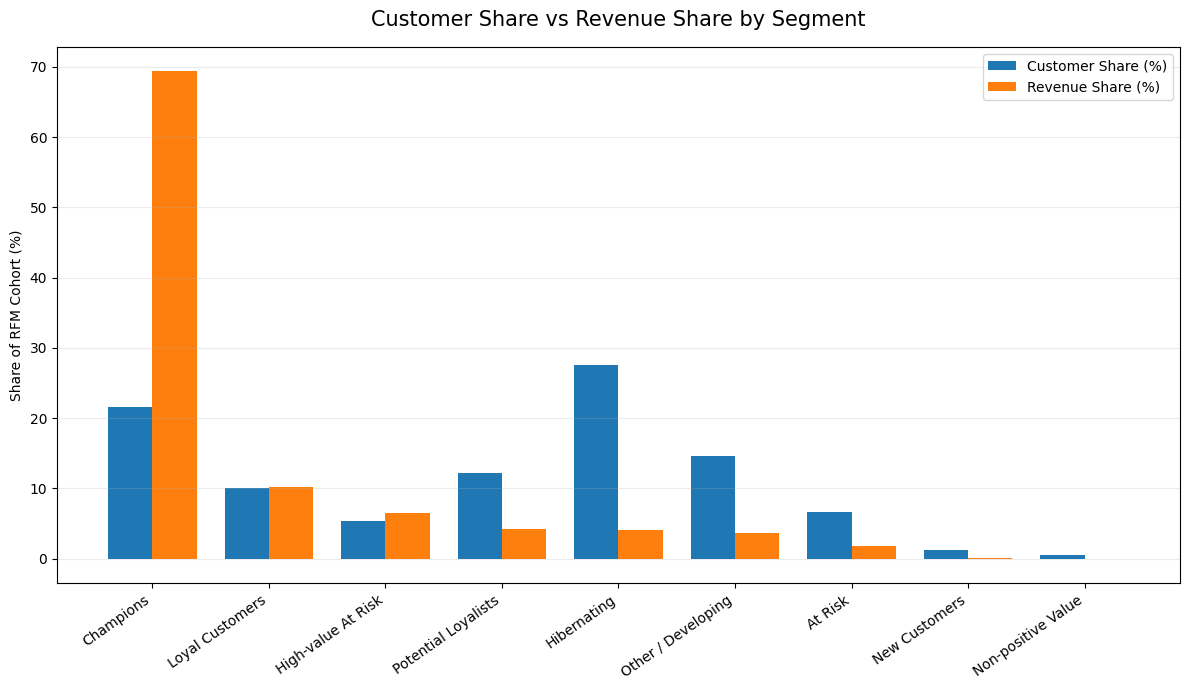

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Sort segments by revenue contribution
plot_data = refined_segment_analysis.sort_values(
    "revenue_share_pct",
    ascending=False
).copy()

x = np.arange(len(plot_data))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    x - width / 2,
    plot_data["customer_share_pct"],
    width,
    label="Customer Share (%)"
)

ax.bar(
    x + width / 2,
    plot_data["revenue_share_pct"],
    width,
    label="Revenue Share (%)"
)

ax.set_title(
    "Customer Share vs Revenue Share by Segment",
    fontsize=15,
    pad=15
)
ax.set_ylabel("Share of RFM Cohort (%)")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["customer_segment_refined"],
    rotation=35,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

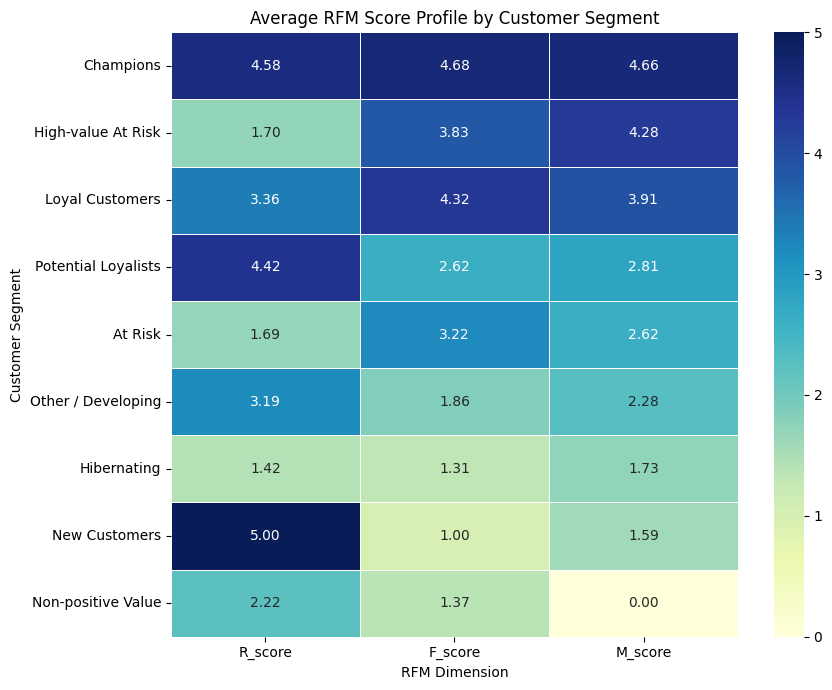

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate average RFM scores by refined segment
rfm_profile = (
    rfm.groupby("customer_segment_refined")
    [["R_score", "F_score", "M_score"]]
    .mean()
    .round(2)
)

# Arrange segments by average monetary score
rfm_profile = rfm_profile.sort_values(
    "M_score",
    ascending=False
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    rfm_profile,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=5
)

plt.title("Average RFM Score Profile by Customer Segment")
plt.xlabel("RFM Dimension")
plt.ylabel("Customer Segment")

plt.tight_layout()
plt.show()

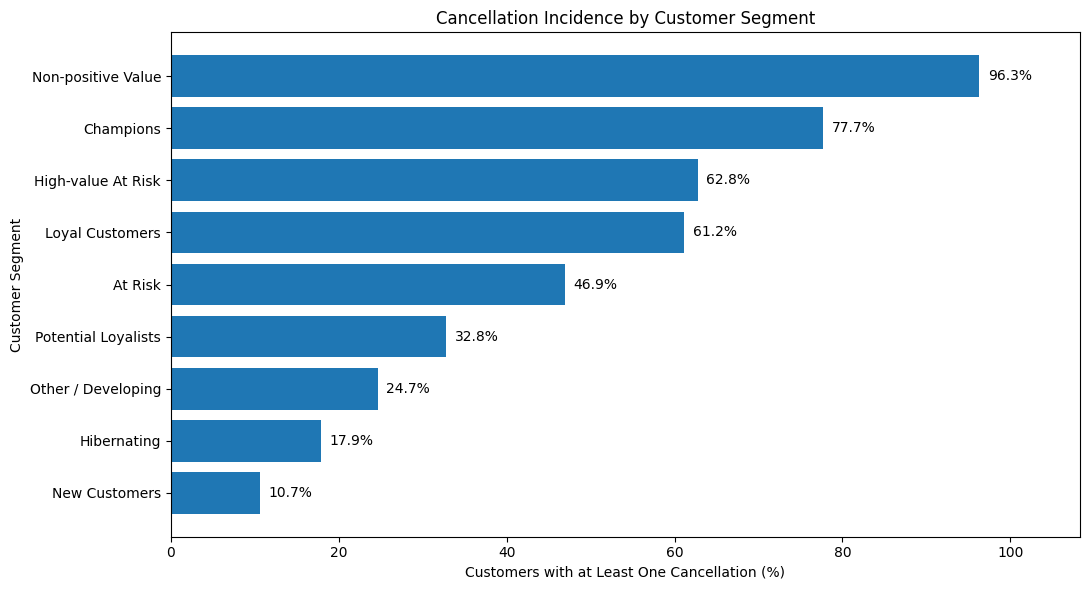

In [23]:
import matplotlib.pyplot as plt

cancellation_plot = cancellation_segment_analysis.sort_values(
    "cancellation_rate_pct",
    ascending=True
).copy()

plt.figure(figsize=(11, 6))

bars = plt.barh(
    cancellation_plot["customer_segment_refined"],
    cancellation_plot["cancellation_rate_pct"]
)

plt.xlabel("Customers with at Least One Cancellation (%)")
plt.ylabel("Customer Segment")
plt.title("Cancellation Incidence by Customer Segment")

for bar, value in zip(
    bars,
    cancellation_plot["cancellation_rate_pct"]
):
    plt.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.xlim(0, cancellation_plot["cancellation_rate_pct"].max() + 12)
plt.tight_layout()
plt.show()


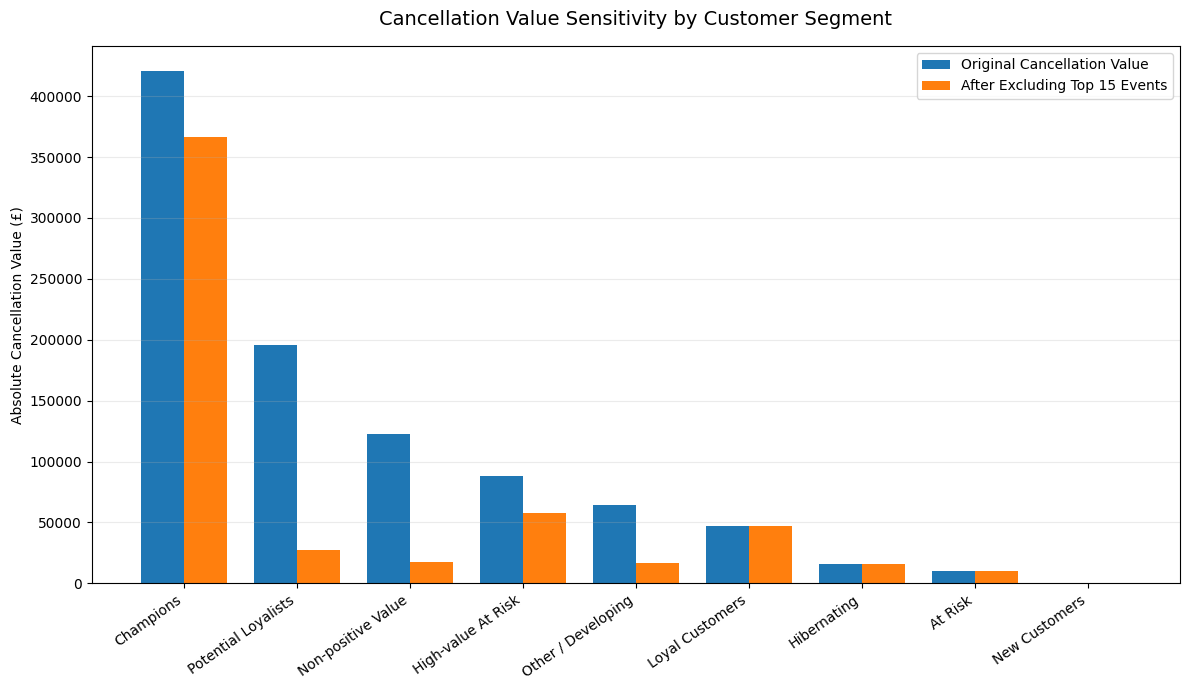

In [24]:
import matplotlib.pyplot as plt
import numpy as np

# Sort segments by original cancellation value
plot_data = cancellation_sensitivity.sort_values(
    "original_cancellation_value"
).copy()

x = np.arange(len(plot_data))
width = 0.38

fig, ax = plt.subplots(figsize=(12, 7))

ax.bar(
    x - width / 2,
    plot_data["original_cancellation_value"].abs(),
    width,
    label="Original Cancellation Value"
)

ax.bar(
    x + width / 2,
    plot_data["adjusted_cancellation_value"].abs(),
    width,
    label="After Excluding Top 15 Events"
)

ax.set_title(
    "Cancellation Value Sensitivity by Customer Segment",
    fontsize=14,
    pad=15
)

ax.set_ylabel("Absolute Cancellation Value (£)")
ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["customer_segment_refined"],
    rotation=35,
    ha="right"
)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [25]:
from pathlib import Path

output_folder = Path("../outputs/tables")
output_folder.mkdir(parents=True, exist_ok=True)

# Save customer-level RFM segmentation
rfm.to_csv(
    output_folder / "customer_rfm_segments.csv",
    index=False
)

# Save segment-level revenue analysis
refined_segment_analysis.to_csv(
    output_folder / "segment_revenue_analysis.csv",
    index=False
)

# Save cancellation analysis
cancellation_segment_analysis.to_csv(
    output_folder / "segment_cancellation_analysis.csv",
    index=False
)

# Save cancellation sensitivity analysis
cancellation_sensitivity.to_csv(
    output_folder / "cancellation_sensitivity_analysis.csv",
    index=False
)

print("Phase 3 tables saved successfully.")
print("Output folder:", output_folder.resolve())

Phase 3 tables saved successfully.
Output folder: C:\Users\monug\OneDrive\Desktop\O712_Customer_Retention\O712_Customer_Retention\outputs\tables


## Final Output — Customer Segmentation Dataset

Export the validated customer-level RFM scores and refined customer segments for use in subsequent analytical notebooks.

In [26]:
from pathlib import Path

output_folder = Path("../outputs/tables")
output_folder.mkdir(parents=True, exist_ok=True)

# Export customer-level segmentation
customer_segments = rfm[
    [
        "Customer ID",
        "recency",
        "frequency",
        "monetary_value",
        "R_score",
        "F_score",
        "M_score",
        "RFM_score",
        "customer_segment_refined"
    ]
].copy()

customer_segments.to_csv(
    output_folder / "customer_rfm_segments.csv",
    index=False
)

print("Customer segmentation exported successfully.")
print("Rows:", len(customer_segments))
print("Unique customers:", customer_segments["Customer ID"].nunique())

display(customer_segments.head())

Customer segmentation exported successfully.
Rows: 5853
Unique customers: 5853


,Customer ID,recency,frequency,monetary_value,R_score,F_score,M_score,RFM_score,customer_segment_refined
0,12346,326,3,-263.68,2,3,0,230,Non-positive Value
1,12347,2,8,4921.53,5,4,5,545,Champions
2,12348,75,5,1658.40,3,4,4,344,Loyal Customers
3,12349,19,3,3654.54,5,3,5,535,Potential Loyalists
4,12350,310,1,294.40,2,1,2,212,Hibernating
